# Lab 4: Denoising

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import urllib
import PIL

rnd_state = np.random.RandomState(12)



## Image Denoising
Sia $\bar{x} \in \mathbb{R}^{d \times d}$ un immagine di $d \times d$ pixels e sia $y \in \mathbb{R}^{d \times d}$ la stessa immagine ma con del rumore i.e.
$$
y = \bar{x} + \epsilon
$$


In [2]:
url = "https://github.com/gpeyre/numerical-tours/blob/master/python/nt_toolbox/data/flowers.png?raw=true"
x_bar = PIL.Image.open(urllib.request.urlopen(url)).convert('L') # immagine reale

x_bar = np.asarray(x_bar).astype('float32')

n, m = x_bar.shape

y = x_bar + 50 * rnd_state.randn(n, m)

In [3]:
print(y.shape)

(502, 502)


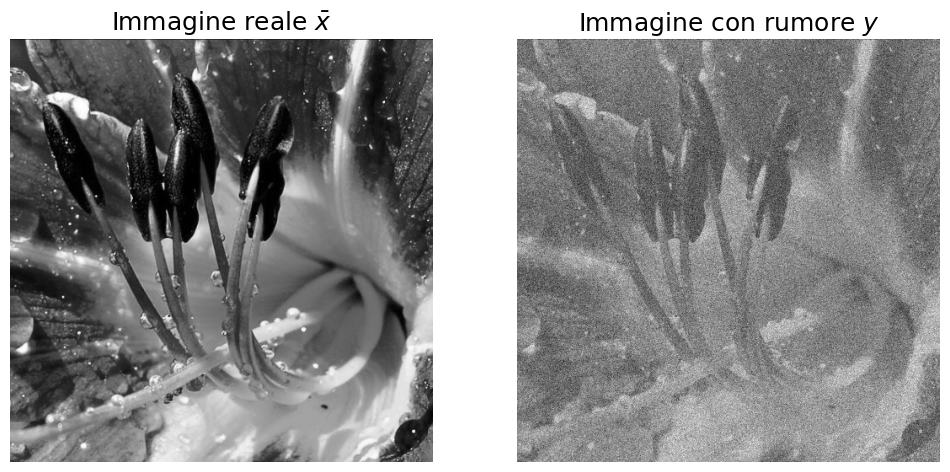

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

ax1.set_title("Immagine reale $\\bar{x}$", fontsize=18)
ax2.set_title("Immagine con rumore $y$", fontsize=18)

ax1.imshow(x_bar, cmap='gray')
ax2.imshow(y, cmap='gray')

ax1.set_axis_off()
ax2.set_axis_off()



Consideriamo quindi il seguente problema di denoising
$$
\min\limits_{x \in \mathbb{R}^{d \times d}} \frac{1}{2}\| x - y\|^2 + \lambda \| \nabla x \|_{1,2}
$$
con $\lambda > 0$ e $\nabla : \mathbb{R}^{d \times d} \to (\mathbb{R}^{2})^{d \times d}$ il gradiente discreto definito come segue
$$
(\nabla x)_{i, j} = ((\partial_1 x)_{i, j}, (\partial_2 x)_{i, j} )
$$
con
$$
(\partial_1 x)_{i, j} = \left\{
  \begin{array}{ll}
    x_{i + 1, j} - x_{i, j} & 1 \leq i \leq d - 1\\
    0 & i= d
   \end{array}
  \right. \qquad (\partial_2 x)_{i, j} = \left\{
  \begin{array}{ll}
    x_{i, j + 1} - x_{i, j} & 1 \leq j \leq d - 1\\
    0 & j= d
   \end{array}
  \right.
$$
Inoltre
$$
\| x \|_{1, 2} = \sum\limits_{i, j = 1}^d \| x_{i, j}\|_2 \qquad x_{i, j} \in \mathbb{R}^2
$$



Definiamo quindi una funzione `disc_grad(x)` che data un'immagine $x$ computa il gradiente discreto e ritorna la coppia $(D_1 x, D_2 x)$


Per calcolare il gradiente discreto possiamo usare la funzione [np.diff](https://numpy.org/doc/stable/reference/generated/numpy.diff.html).
___
**Esempio**

Nota che data una matrice
$$
A = \begin{bmatrix}
1 & 2 & 3\\
4 & 5 & 6\\
7 & 8 & 9
\end{bmatrix}
$$

In [5]:
A = np.array([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0], [7.0, 8.0, 9.0]] ).reshape(-1, 3)

out1 = np.diff(A, axis=0)
# out1 e` una matrice 2 x 3 contenente le differenze tra le entrate calcolate sulle colonne  i.e.
# out1[i, j] = A[i + 1, j] - A[i, j]
out2 = np.diff(A, axis=1)
# out2 e` una matrice 3 x 2 contenente le differenze tra le entrate calcolate sulle righe i.e.
# out2[i, j] = A[i, j + 1] - A[i, j]


Nota che `out1` e\` una matrice $2 \times 3$ contenente le differenze tra le entrate calcolate sulle colonne i.e.
$$
out1[i, j] = A[i + 1, j] - A[i, j]
$$

In [6]:
print("OUT1 = ", out1)
print("OUT2 = ", out2)
A[1:-1,:]

OUT1 =  [[3. 3. 3.]
 [3. 3. 3.]]
OUT2 =  [[1. 1.]
 [1. 1.]
 [1. 1.]]


array([[4., 5., 6.]])

___

In [7]:
def disc_grad(x):
  # TODO: ritorna il gradiente discreto in x
  grad = np.zeros([*x.shape, 2])
  # nota che x e` una matrice d x d
  # calcoliamo la differenza finita dei pixel sulle colonne (axis = 0)
  grad[:-1, :, 0] = np.diff(x, axis=0)
  # calcoliamo la differenza finita dei pixel sulle righe (axis = 1)
  grad[:, :-1, 1] = np.diff(x, axis=1)
  return grad


Definito il gradiente discreto, possiamo implementare la funzione target come segue

In [8]:
def f(x, lam):
  return np.linalg.norm(x-y)**2/2 + lam*np.sum(np.sqrt(np.sum(disc_grad(x)**2,2)))

Ora possiamo calcolare $\nabla \bar{x}$ e plottarlo

Text(0.5, 1.0, 'd/dy')

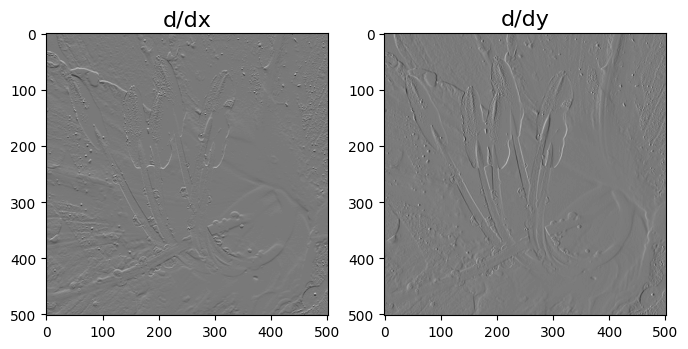

In [9]:
grad =  disc_grad(x_bar)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))
ax1.imshow(grad[:, :, 0], cmap='gray')
ax1.set_title("d/dx", fontsize=16)
ax2.imshow(grad[:, :, 1], cmap='gray')
ax2.set_title("d/dy", fontsize=16)


Nota che non possiamo usare direttamente l'algoritmo prossimale del gradiente dato che il prox della total variation non e\` in forma chiusa.
Consideriamo quindi il problema duale
$$
\min\limits_{u \in (\mathbb{R}^2)^{n \times m}} \frac{1}{2} \|y - \nabla^* u \|^2 - \frac{1}{2} \| y \|^2 + 1_{B_\lambda(0)^{d \times d} (u)}
$$
Dove $B_\lambda(0)$ e\` la palla in $\mathbb{R}^2$ centrata in $0$ e
$$
\nabla^* u = - \text{div} (u) : (\mathbb{R}^2)^{d \times d} \to \mathbb{R}^{d \times d}
$$

definita come segue
$$
(\text{div}(u))_{i,j} = (\text{div}(u^{(1)}, u^{(2)}))_{i,j} = \left\{
  \begin{array}{ll}
    u^{(1)}_{i, j} - u^{(1)}_{i - 1, j}  & 1 < i < d\\
    u^{(1)}_{1, j}  & i = 1\\
    - u^{(1)}_{d - 1, j} & i = d
  \end{array}
  \right.  + \left\{
  \begin{array}{ll}
    u^{(2)}_{i, j} - u^{(2)}_{i, j-1}  & 1 < j < d\\
    u^{(2)}_{i, 1}  & j = 1\\
    - u^{(2)}_{i, d - 1} & j = d
  \end{array}
  \right.
$$


Definiamo ora una funzione `grad_star(u)` che presa una coppia `u = (u_1, u_2)` ritorna $- \text{div}(u^{(1)},u^{(2)} )$

Nota che il parametro `u` e\` un oggetto con shape `(d, d, 2)` dove l'ultimo asse denota la componente i.e. `u[i, j, 0]` corrisponde a $u_{i,j}^{(1)}$


In [10]:
def grad_star(u):
  # TODO: ritorna il gradiente della coniugata in u

  div = np.zeros((u.shape[0], u.shape[1])) # costruiamo una matrice contenente zero
  # caso i = 1: assegnamo la prima riga
  div[0, :] = u[0,:,0]
  # caso 1 < i < d: calcoliamo e assegnamo le differenze tra pixel sulle colonne (axis=0) escludendo l'ultimo pixel (i.e. u[:-1, :, 0])
  div[1:-1, :] =np.diff(u[:-1,:, 0], axis=0)
  # caso i = d: calcoliamo la penultima riga
  div[-1, :] = -u[-2,:,0]

  # caso j = 1: aggiungiamo la prima colonna
  div[:, 0] += u[:,0,1]
  # caso 1 < j < d: calcoliamo le differenze tra pixel sulle righe (axis=1) escludendo l'ultimo pixel (i.e. u[:, :-1, 1])
  div[:, 1:-1] +=np.diff(u[:,:-1, 1], axis=1)
  # caso j = d: aggiungiamo la penultima colonna
  div[:, -1] += -u[:,-2,1]
  return -div




La funzione target nel duale e\` quindi

In [11]:
def f_star(u):
  return 1/2 * np.linalg.norm(y-grad_star(u))**2 - (np.linalg.norm(y)**2)/2

Possiamo quindi risolvere il problema usando Forward-Backward nel duale.
L'iterazione sara` quindi la seguente
$$
x^{(k)} = y - \nabla^*u^{(k)}\\
u^{(k + 1)}_{i, j} = P_{B_\lambda(0)}(u^{(k)}_{i, j} + \gamma (\nabla x^{(k)})_{i, j} )
$$
con $\gamma < 2/L$. Nota che
$$
L = \| \nabla \nabla^* \| \leq 8.
$$

Dove $P_{B_\lambda(0)}$ e\` l'operatore di proiezione sulla palla in $\mathbb{R}^2$ di raggio $\lambda$ centrata in $0$ i.e.
$$
P_{B_\lambda(0)^{d \times d}}(u) = (P_{B_\lambda(0)}(u_{i, j}))_{i, j}, \qquad P_{B_\lambda(0)}(u_{i, j}) = \left\{
\begin{array}{ll}
  u_{i, j} & \|u_{i, j}\|_{2} \leq \lambda\\
  \lambda\frac{u_{i, j}}{\|u_{i,j}\|_2} & \text{altrimenti}
\end{array}
  \right.
$$

Implementiamo quindi l'operatore con la funzione `project_B(u,lam)`



In [12]:
def project_B(u, lam):
  return u/np.maximum(np.linalg.norm(u,axis=2,ord=2, keepdims=True)/lam,1)
  # TODO: implementa la proiezione
  #for i in range(u.shape[0]):
    #for j in range(u.shape[1]):
      #if np.linalg.norm(u[i,j,:])<= lam:
        #return u[i,j,:]
      #else:
        #return (lam/np.linalg.norm(u[i,j,:]))*u[i,j,:]


Implementiamo quindi la funzione
```
dual_fb(u0, gamma, lam, T)
```
dove:
- `u0`: primo guess (nel duale)
- `gamma`: stepsize
- `lam`: parametro di regolarizzazione
- `T`: numero di iterazioni

In [13]:
def dual_fb(u0, gamma, lam, T):
  x_iters, u_iters = np.empty((T , u0.shape[0], u0.shape[1])), np.empty((T , u0.shape[0], u0.shape[1], u0.shape[2]))
  f_vals, f_star_vals = np.empty(T + 1), np.empty(T+ 1)
  u = u0.copy()
  #print(u)
  x = np.empty((u0.shape[0], u0.shape[1]))
  #print(u.shape())
  h=grad_star(u)
  f_vals[0] = f(y - grad_star(u), lam)
  f_star_vals[0] = f_star(u)
  for t in range(T):

    # TODO: implementa l'iterazione di FB per il problema duale

    x = y-grad_star(u)
    u = project_B(u+gamma*disc_grad(x), lam)

    x_iters[t] = x.copy()
    u_iters[t] = u.copy()
    f_vals[t + 1] = f(x, lam)
    f_star_vals[t + 1] = f_star(u)
  return x_iters, u_iters, f_vals, f_star_vals




Eseguiamo ora l'algoritmo

In [14]:
u0 = np.zeros((n, m, 2))
# TODO: scegli un valore per lo step-size
gamma = 1/8
lam = 45.0
T = 500

#grad_star(u0)

# TODO: Esegui l'algoritmo implementato
x_iters, u_iters, f_vals, f_star_vals = dual_fb(u0, gamma, lam, T)

Plottiamo $f$ e $f^*$ sulle iterate computate

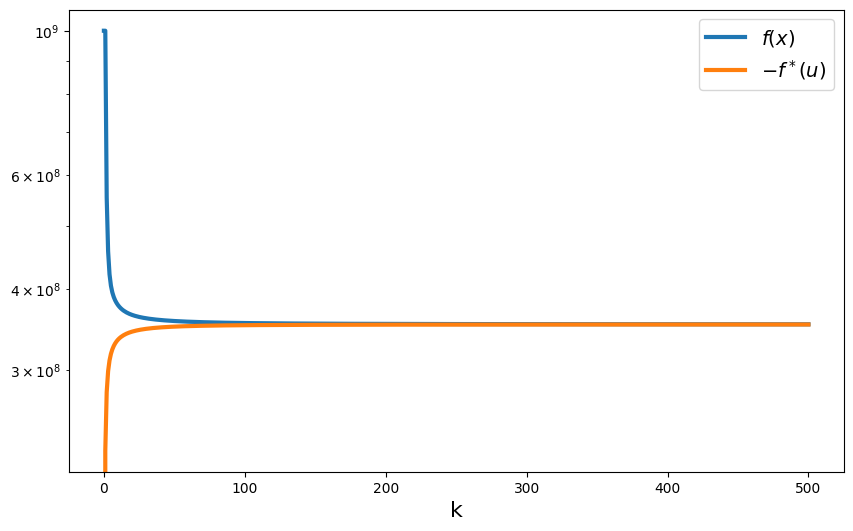

In [15]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(T + 1), f_vals, '-', lw=3, label="$f(x)$")
ax.plot(range(T + 1), -f_star_vals, '-', lw=3, label="$- f^*(u)$")
ax.set_yscale('log')
ax.set_xlabel("k", fontsize=16)
ax.legend(fontsize=14)

Plottiamo anche l'optimality gap

Text(0.5, 1.0, 'Optimality Gap')

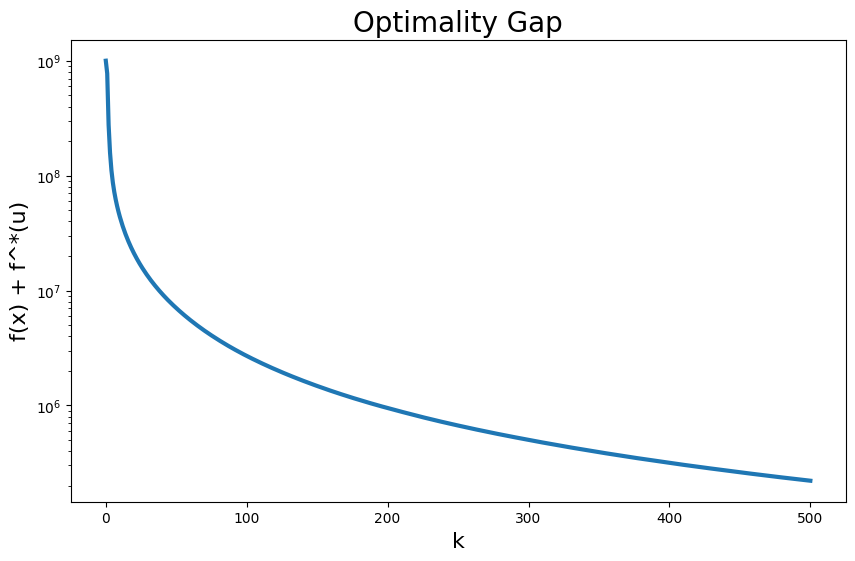

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(T + 1), f_vals + f_star_vals, '-', lw=3)
ax.set_yscale('log')
ax.set_xlabel("k", fontsize=16)
ax.set_ylabel("f(x) + f^*(u)", fontsize=16)
ax.set_title("Optimality Gap", fontsize=20)

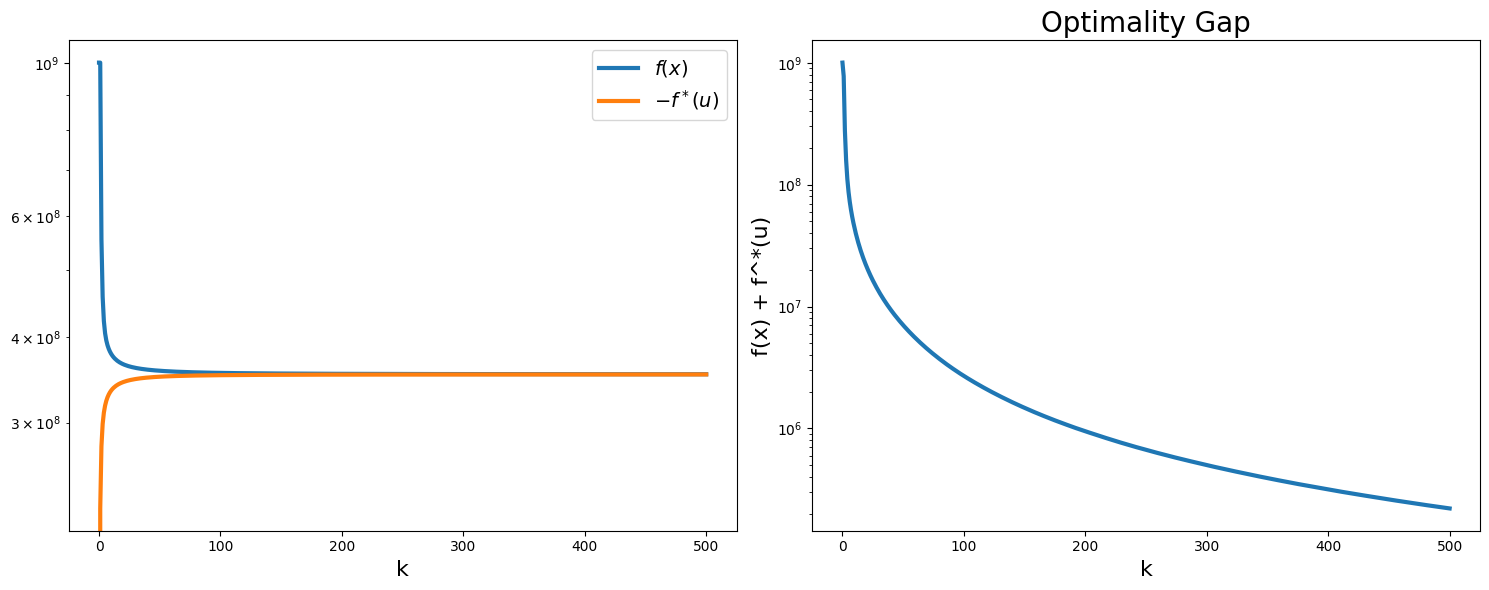

In [17]:
# First plot
fig, axs = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1
axs[0].plot(range(T + 1), f_vals, '-', lw=3, label="$f(x)$")
axs[0].plot(range(T + 1), -f_star_vals, '-', lw=3, label="$- f^*(u)$")
axs[0].set_yscale('log')
axs[0].set_xlabel("k", fontsize=16)
axs[0].legend(fontsize=14)

# Plot 2
axs[1].plot(range(T + 1), f_vals + f_star_vals, '-', lw=3)
axs[1].set_yscale('log')
axs[1].set_xlabel("k", fontsize=16)
axs[1].set_ylabel("f(x) + f^*(u)", fontsize=16)
axs[1].set_title("Optimality Gap", fontsize=20)

plt.tight_layout()
plt.show()

Plottiamo anche l'immagine ricostruita

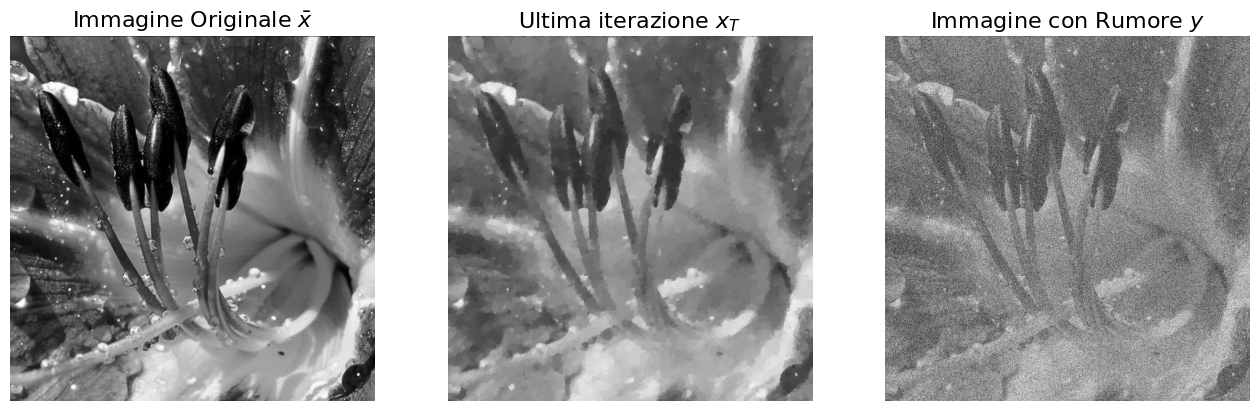

In [18]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 8))
ax1.imshow(x_bar, cmap='gray')
ax2.imshow(x_iters[-1], cmap='gray')
ax3.imshow(y, cmap='gray')

ax1.set_axis_off()
ax2.set_axis_off()
ax3.set_axis_off()

_ = ax1.set_title("Immagine Originale $\\bar{x}$", fontsize=16)
_ = ax2.set_title("Ultima iterazione $x_T$", fontsize=16)
_ = ax3.set_title("Immagine con Rumore $y$", fontsize=16)


#**Variazione Totale**



In [19]:
u0 = np.zeros((n, m, 2))

# TODO: scegli uno step-size
gamma = 1/8
lambdas=[20,45,60, 80]
T = 500

x_iters_lambda = []

# TODO: Esegui l'algoritmo implementato
for lam in lambdas:
  x_iters_lam,_,_,_= dual_fb(u0, gamma, lam, T)
  # Store results
  x_iters_lambda.append(x_iters_lam)

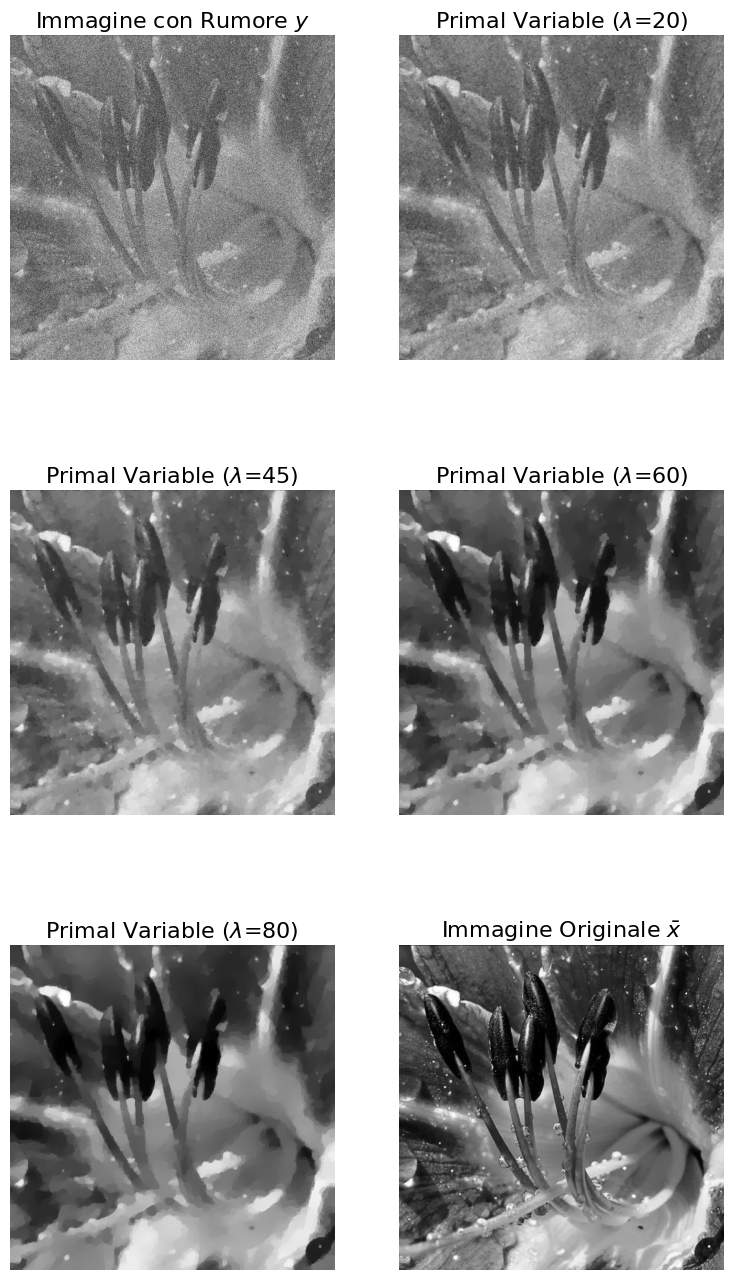

In [34]:
import matplotlib.pyplot as plt

# Initialize the figure and subplots
fig, axs = plt.subplots(3, 2, figsize=(14, 14))

# Plot x_bar in the first subplot
axs[0, 0].imshow(y, cmap='gray')
axs[0, 0].set_title("Immagine con Rumore $y$", fontsize=16)
axs[0, 0].set_axis_off()

# Iterate over lambdas for the middle four subplots
for i, lam in enumerate(lambdas):
    # Plot the primal variable (x_iters_lam) for the current lambda
    ax_row = (i + 1) // 2
    ax_col = (i + 1) % 2
    axs[ax_row, ax_col].imshow(x_iters_lambda[i][-1], cmap='gray')
    axs[ax_row, ax_col].set_title(f"Primal Variable ($\\lambda$={lam})", fontsize=16)
    axs[ax_row, ax_col].set_axis_off()

# Plot y in the last subplot
axs[2, 1].imshow(x_bar, cmap='gray')
axs[2, 1].set_title("Immagine Originale $\\bar{x}$", fontsize=16)
axs[2, 1].set_axis_off()

plt.subplots_adjust(left=0.45, right=0.96, bottom=0.05, top=0.95, hspace=0.3, wspace=0.2)


plt.show()



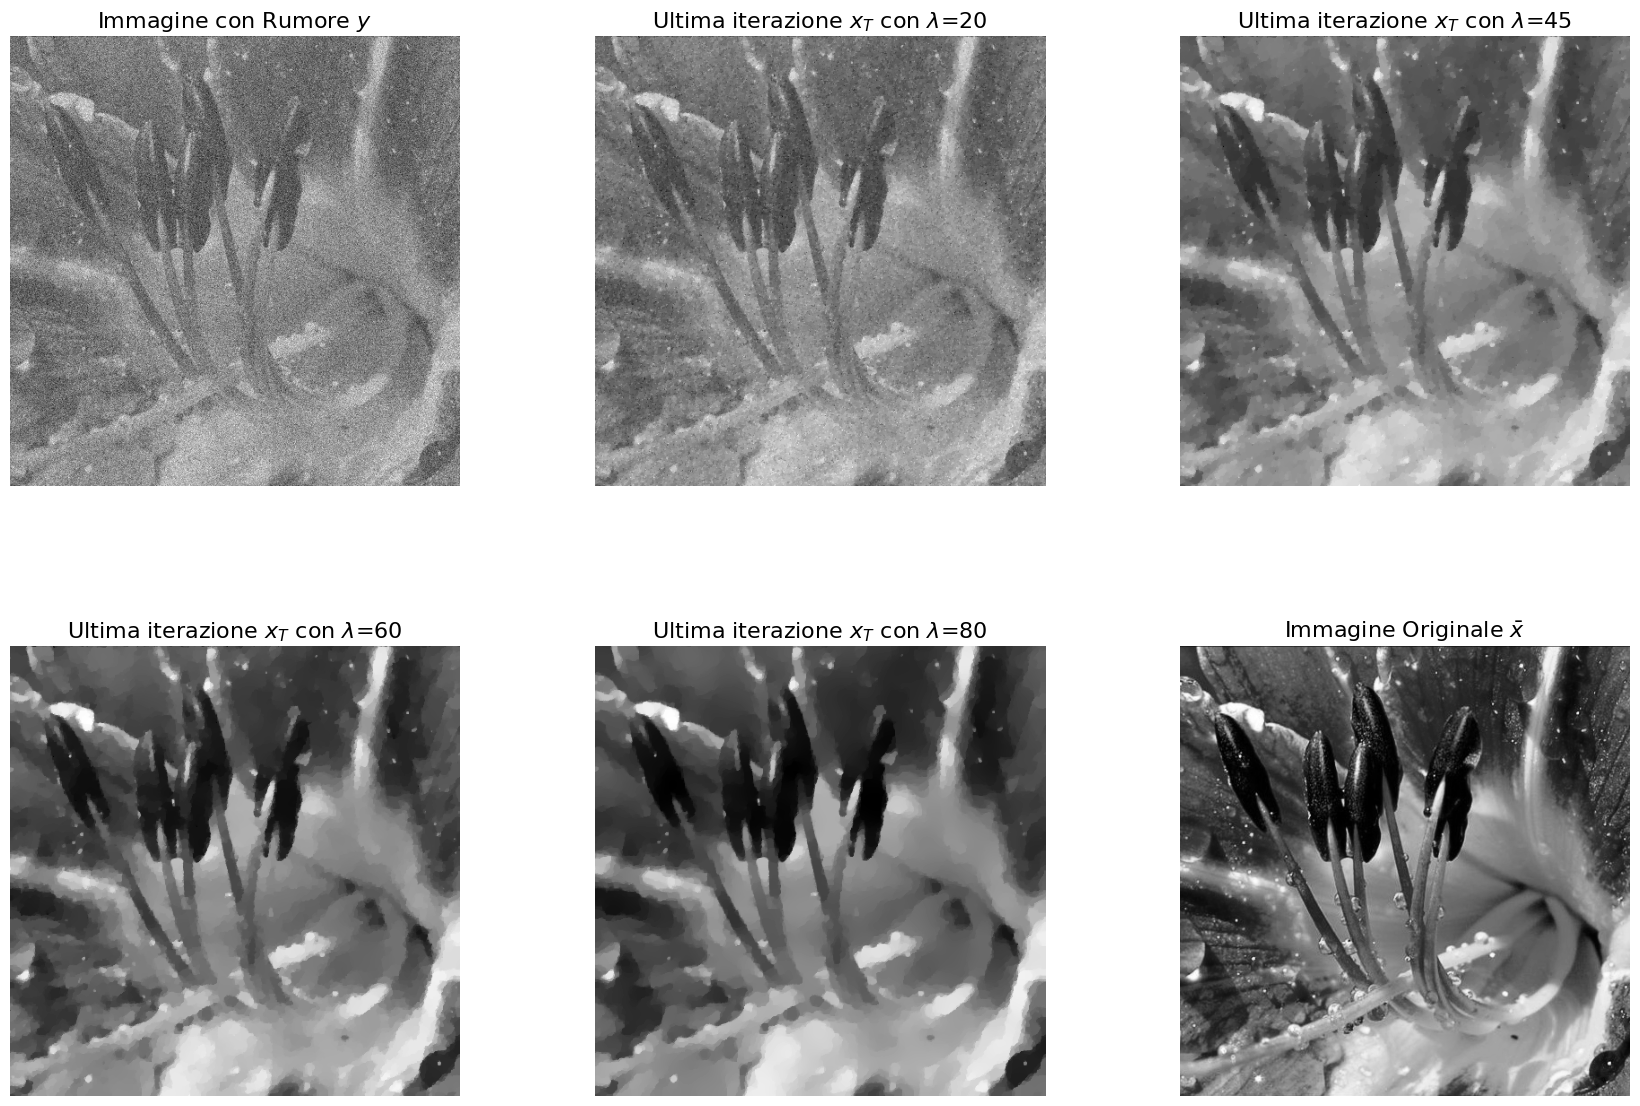

In [61]:
import matplotlib.pyplot as plt

# Initialize the figure and subplots
fig, axs = plt.subplots(2, 3, figsize=(18, 12))

# Plot x_bar in the first subplot
axs[1, 2].imshow(x_bar, cmap='gray')
axs[1, 2].set_title("Immagine Originale $\\bar{x}$", fontsize=16)
axs[1, 2].set_axis_off()

# Plot y in the last subplot
axs[0, 0].imshow(y, cmap='gray')
axs[0, 0].set_title("Immagine con Rumore $y$", fontsize=16)
axs[0, 0].set_axis_off()

# Iterate over lambdas for the middle four subplots
for i, lam in enumerate(lambdas):
    if i < 2:  # We leave the second subplot in the second row empty
        # Plot the primal variable (x_iters_lam) for the current lambda
        ax_col = i + 1
        axs[0, ax_col].imshow(x_iters_lambda[i][-1], cmap='gray')
        axs[0, ax_col].set_title(f"Ultima iterazione $x_T$ con $\\lambda$={lam}", fontsize=16)
        axs[0, ax_col].set_axis_off()
    else:
        ax_col = i -2
        axs[1, ax_col].imshow(x_iters_lambda[i][-1], cmap='gray')
        axs[1, ax_col].set_title(f"Ultima iterazione $x_T$ con $\\lambda$={lam}", fontsize=16)
        axs[1, ax_col].set_axis_off()

plt.subplots_adjust(left=0.05, right=0.95, bottom=0.05, top=0.95, hspace=0.3, wspace=0.3)

plt.show()




# FISTA nel duale
Come visto a lezione e nel laboratorio precedente, l'algoritmo puo\` essere esteso includendo l'inerzia.

L'iterazione e\` quindi definita come segue
$$
v^{(k)} = y - \nabla^* z^{(k)}\\
u^{(k + 1)} = P_{B_\lambda(0)^{n \times m}}(z^{(k)} + \gamma \nabla v^{(k)})\\
z^{(k + 1)} = u^{(k + 1)} + \beta_{k + 1} (u^{(k + 1)} - u^{(k)})\\
x^{(k + 1)} = y - \nabla^* u^{(k + 1)}
$$
Dove $\beta_k$ e\` il parametro d'inerzia
$$
\beta_{k + 1} = \frac{t_k - 1}{t_{k + 1}}
$$

Inoltre, $u^{(0)} = v^{(0)}$, $z^{(0)} = y - \nabla^* u^{(0)}$ e $\gamma < 1/8.$

Implementiamo ora una funzione `beta(tk, k)` usando uno dei criteri visti nelle precedenti lezioni (e.g. Nesterov o Chambolle & Dossal).

Tale funzione prende in input $t_k$ e $k$ e ritorna $\beta_{k + 1}$ e $t_{k + 1}$.

In [ ]:
def beta(tk, k, alpha):
  # TODO: implementa uno schema per calcolare il parametro d'inerzia Chambolle che è uguale a Nesterov per alpha=2
  t_next = (k+alpha)/alpha
  beta=(tk - 1) / t_next
  return beta, t_next

Implementiamo una funzione
```
dual_fista(u0, beta, gamma, lam, T)
```
Dove:
- `u0`: primo guess (nel duale)
- `beta`: funzione che calcola $\beta_{k + 1}$
- `gamma`: stepsize
- `lam`: parametro di regolarizzazione
- `T`: numero di iterazioni

In [ ]:
def dual_fista(u0, beta, gamma, lam, T, alpha):
  x_iters, u_iters = np.empty((T, u0.shape[0], u0.shape[1])), np.empty((T, u0.shape[0], u0.shape[1], u0.shape[2]))
  f_vals, f_star_vals = np.empty(T + 1), np.empty(T + 1)
  u = u0.copy()
  x = np.empty((u0.shape[0], u0.shape[1]))
  tk = 1
  z = u.copy()

  f_vals[0] = f(y - grad_star(u), lam)
  f_star_vals[0] = f_star(u)

  for t in range(T):
    beta_n, tk = beta(tk, t, alpha)
    # TODO: implementa l'iterazione di FISTA per il problema duale
    u_pred=u
    u =project_B(z+gamma*disc_grad(y-grad_star(z)),lam)
    z=u+beta_n*(u-u_pred)
    x = y-grad_star(u)

    x_iters[t] = x.copy()
    u_iters[t] = u.copy()
    f_vals[t + 1] = f(x, lam)
    f_star_vals[t + 1] = f_star(u)
  return x_iters, u_iters, f_vals, f_star_vals

In [ ]:
u0 = np.zeros((n, m, 2))

# TODO: scegli uno step-size
gamma = 1/8
alpha=5
lam = 45.0
T = 500

# TODO: Esegui l'algoritmo implementato
x_iters_fista, _, f_vals_fista, f_star_vals_fista = dual_fista(u0, beta, gamma, lam, T, alpha)

Confrontiamo l'optimality gap ottenuto con quello ottenuto da FB.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(T + 1), f_vals + f_star_vals, '-', lw=3, label='dual FB')
ax.plot(range(T + 1), f_vals_fista + f_star_vals_fista, '-', lw=3, label='dual FISTA')
ax.set_yscale('log')
ax.set_xlabel("k", fontsize=16)
ax.set_ylabel("f(x) + f^*(u)", fontsize=16)
ax.set_title("Optimality Gap", fontsize=20)
ax.legend(fontsize=14)

In [ ]:
fig, ((ax1, ax4), (ax2, ax3)) = plt.subplots(2, 2, figsize=(18, 8))

ax1.imshow(x_bar, cmap='gray')
ax2.imshow(x_iters[-1], cmap='gray')
ax3.imshow(x_iters_fista[-1], cmap='gray')
ax4.imshow(y, cmap='gray')

ax1.set_axis_off()
ax2.set_axis_off()
ax3.set_axis_off()
ax4.set_axis_off()

_ = ax1.set_title("Immagine Originale $\\bar{x}$", fontsize=16)
_ = ax2.set_title("Ultima iterazione FB $x^{FB}_T$", fontsize=16)
_ = ax3.set_title("Ultima iterazione FISTA $x^{FISTA}_T$", fontsize=16)
_ = ax4.set_title("Immagine con Rumore $y$", fontsize=16)

plt.subplots_adjust(left=0.05, right=0.4, bottom=0.05, top=0.95)

plt.show()

In [ ]:
u0 = np.zeros((n, m, 2))

# TODO: scegli uno step-size
gamma = 1/8
alphas=[2,10,5]
T = 500

f_vals_fistas = []
f_star_vals_fistas = []
x_iters_fistas = []

# TODO: Esegui l'algoritmo implementato
for alpha in alphas:
  x_iters_fista, _, f_vals_fista, f_star_vals_fista = dual_fista(u0, beta, gamma, lam, T, alpha)
  # Store results
  x_iters_fistas.append(x_iters_fista)
  f_vals_fistas.append(f_vals_fista)
  f_star_vals_fistas.append(f_star_vals_fista)

In [ ]:

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(range(T + 1), f_vals + f_star_vals, '-', lw=3, label='dual FB')
for alpha, f_vals_fista, f_star_vals_fista in zip(alphas, f_vals_fistas, f_star_vals_fistas):
    ax.plot(range(T + 1), f_vals_fista + f_star_vals_fista, '-', lw=3, label=f'dual FISTA, alpha={alpha}')

ax.set_yscale('log')
ax.set_xlabel("k", fontsize=16)
ax.set_ylabel("f(x) + f^*(u)", fontsize=16)
ax.set_title("Optimality Gap", fontsize=20)
ax.legend(fontsize=14)
plt.show()

In [ ]:
fig, (ax1, ax2, ax3, ax4) = plt.subplots(1, 4, figsize=(18, 8))
ax1.imshow(x_bar, cmap='gray')
ax2.imshow(x_iters[-1], cmap='gray')
ax3.imshow(x_iters_fista[-1], cmap='gray')
ax4.imshow(y, cmap='gray')

ax1.set_axis_off()
ax2.set_axis_off()
ax3.set_axis_off()
ax4.set_axis_off()

_ = ax1.set_title("Immagine Originale $\\bar{x}$", fontsize=16)
_ = ax2.set_title("Ultima iterazione FB $x^{FB}_T$", fontsize=16)
_ = ax3.set_title("Ultima iterazione FISTA $x^{FISTA}_T$", fontsize=16)
_ = ax4.set_title("Immagine con Rumore $y$", fontsize=16)
